In [1]:
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage, RemoveMessage

In [2]:
load_dotenv()

True

In [3]:
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [4]:
class ChatState(MessagesState):
    summary: str

In [5]:
def chat_node(state: ChatState):
    messages = []

    if state["messages"]:
        messages.append({
            "role": "system",
            "content": f"Conversation summary:\n{state["summary"]}"
        })

        messages.extend(state["messages"])

        print(messages)

        response = llm.invoke(messages)

        return {"messages": [response]}

In [6]:
def summarize_conversation(state: ChatState):

    existing_summary = state["summary"]

    # Build summarization prompt
    if existing_summary:
        prompt = (
            f"Existing summary:\n{existing_summary}\n\n"
            "Extend the summary using the new conversation above."
        )
    else:
        prompt = "Summarize the conversation above."

    messages_for_summary = state["messages"] + [
        HumanMessage(content=prompt)
    ]

    response = llm.invoke(messages_for_summary)

    # keep only last 2 messages
    messages_to_delete = state["messages"][:-2]

    return {
        "summary": response.content,
        "messages": [RemoveMessage(id=m.id) for m in messages_to_delete]
    }

In [7]:
def should_summarize(state: ChatState):
    return len(state["messages"]) > 6

In [8]:
builder = StateGraph(ChatState)

builder.add_node("chat", chat_node)
builder.add_node("summarize", summarize_conversation)

builder.add_edge(START, "chat")
builder.add_conditional_edges(
    "chat", 
    should_summarize,
    {
        True: "summarize",
        False: "__end__",
    }
)

builder.add_edge("summarize", "__end__")

In [9]:
checkpointer = InMemorySaver()

graph = builder.compile(checkpointer=checkpointer)

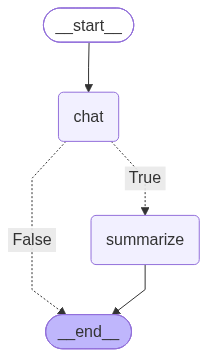

In [10]:
graph

In [11]:
CONFIG = {"configurable": {"thread_id": "t1"}}

In [12]:
# Gives the current version of the state
def show_state():
    snap = graph.get_state(config=CONFIG)
    vals = snap.values

    print("\n==== STATE ====")
    print("summary:", vals.get("summary", ""))
    print("num_messages:", len(vals.get("messages", [])))
    print("messages:")

    for m in vals.get("messages", []):
        print("-", type(m).__name__, ":", m.content[:80])

In [13]:
output = graph.invoke({"messages": [HumanMessage(content="System Design")], "summary": ""}, config=CONFIG)

print(output)

show_state()

[{'role': 'system', 'content': 'Conversation summary:\n'}, HumanMessage(content='System Design', additional_kwargs={}, response_metadata={}, id='0b39e032-97bc-4eb8-af2b-f6670417abcf')]
{'messages': [HumanMessage(content='System Design', additional_kwargs={}, response_metadata={}, id='0b39e032-97bc-4eb8-af2b-f6670417abcf'), AIMessage(content=[{'type': 'text', 'text': 'System Design is a vast and crucial topic in software engineering. It’s the process of defining the architecture, components, modules, interfaces, and data for a system to satisfy specified requirements.\n\nTo give you the most relevant information, **what specific area of System Design would you like to dive into?** \n\nHere are some common ways we can structure this:\n\n### 1. Core Concepts & Fundamentals\n*   **Scalability:** Vertical vs. Horizontal scaling, Load Balancers.\n*   **Databases:** SQL vs. NoSQL, Replication, Sharding, CAP Theorem, ACID vs. BASE.\n*   **Caching:** Redis/Memcached, Cache invalidation strategi

In [14]:
output = graph.invoke({"messages": [HumanMessage(content="Who is Nikola Tesla?")]}, config=CONFIG)

print(output)

show_state()

[{'role': 'system', 'content': 'Conversation summary:\n'}, HumanMessage(content='System Design', additional_kwargs={}, response_metadata={}, id='0b39e032-97bc-4eb8-af2b-f6670417abcf'), AIMessage(content=[{'type': 'text', 'text': 'System Design is a vast and crucial topic in software engineering. It’s the process of defining the architecture, components, modules, interfaces, and data for a system to satisfy specified requirements.\n\nTo give you the most relevant information, **what specific area of System Design would you like to dive into?** \n\nHere are some common ways we can structure this:\n\n### 1. Core Concepts & Fundamentals\n*   **Scalability:** Vertical vs. Horizontal scaling, Load Balancers.\n*   **Databases:** SQL vs. NoSQL, Replication, Sharding, CAP Theorem, ACID vs. BASE.\n*   **Caching:** Redis/Memcached, Cache invalidation strategies (Write-through, Write-around, Cache-aside).\n*   **Messaging & Streaming:** Message queues (RabbitMQ, Kafka), Event-driven architecture.\

In [15]:
output = graph.invoke({"messages": [HumanMessage(content="What are some of Tesla's famous works?")]}, config=CONFIG)

print(output)

show_state()

[{'role': 'system', 'content': 'Conversation summary:\n'}, HumanMessage(content='System Design', additional_kwargs={}, response_metadata={}, id='0b39e032-97bc-4eb8-af2b-f6670417abcf'), AIMessage(content=[{'type': 'text', 'text': 'System Design is a vast and crucial topic in software engineering. It’s the process of defining the architecture, components, modules, interfaces, and data for a system to satisfy specified requirements.\n\nTo give you the most relevant information, **what specific area of System Design would you like to dive into?** \n\nHere are some common ways we can structure this:\n\n### 1. Core Concepts & Fundamentals\n*   **Scalability:** Vertical vs. Horizontal scaling, Load Balancers.\n*   **Databases:** SQL vs. NoSQL, Replication, Sharding, CAP Theorem, ACID vs. BASE.\n*   **Caching:** Redis/Memcached, Cache invalidation strategies (Write-through, Write-around, Cache-aside).\n*   **Messaging & Streaming:** Message queues (RabbitMQ, Kafka), Event-driven architecture.\

In [16]:
output = graph.invoke({"messages": [HumanMessage(content="Explain Tesla Coil.")]}, config=CONFIG)

print(output)

show_state()

[{'role': 'system', 'content': 'Conversation summary:\n'}, HumanMessage(content='System Design', additional_kwargs={}, response_metadata={}, id='0b39e032-97bc-4eb8-af2b-f6670417abcf'), AIMessage(content=[{'type': 'text', 'text': 'System Design is a vast and crucial topic in software engineering. It’s the process of defining the architecture, components, modules, interfaces, and data for a system to satisfy specified requirements.\n\nTo give you the most relevant information, **what specific area of System Design would you like to dive into?** \n\nHere are some common ways we can structure this:\n\n### 1. Core Concepts & Fundamentals\n*   **Scalability:** Vertical vs. Horizontal scaling, Load Balancers.\n*   **Databases:** SQL vs. NoSQL, Replication, Sharding, CAP Theorem, ACID vs. BASE.\n*   **Caching:** Redis/Memcached, Cache invalidation strategies (Write-through, Write-around, Cache-aside).\n*   **Messaging & Streaming:** Message queues (RabbitMQ, Kafka), Event-driven architecture.\